# P4.01 — Do ETS and ARIMA beat naive forecasts? National real prices and the cost of ownership

**Questions:** RQ10.1 (how prices and affordability are likely to evolve over 5 to 10 years). This notebook
settles the *statistical* part: which forecaster to use and how wide its intervals must be. Scenarios (rates,
income, supply, policy) come in the simulator.

**Series (quarterly, national, 2009Q1 to 2026Q2, 70 quarters):**
1. real house price index (INE, deflated by CPI, 2024 euros);
2. **ownership cost index** = real price index × monthly payment per 100,000 EUR of a 30-year loan at the quarter's
   average new-loan rate, rebased to 100 in 2024 (`features/affordability.py`). It is the affordability indicator
   that can be built quarterly: it moves with prices *and* the cost of credit, at constant real income. Income is
   annual only, so the burden (cost over income) is formed in the simulator from an income scenario.

**Methods** (`src/pthousing/analysis/forecasting.py`), all on logs: naive, seasonal naive, drift, ETS (six forms
chosen by AICc) and ARIMA(p,1,q) with or without drift (p, q ≤ 2, by AICc). No machine learning: the brief asks
a more complex model to beat these first, and none is tried.

**Validation:** rolling origin. The first origin has 36 quarters (to 2017Q4); every method is refitted at each
origin using data up to it only, and forecasts 1 to 8 quarters ahead. Metrics: RMSE (log points), MASE, bias,
and the coverage of the 80% and 95% intervals. **Selection rule, fixed before looking:** the method with the
lowest mean RMSE over horizons 1 to 8 on *both* series is used for the forecast; ties go to the simpler method.

In [1]:
import numpy as np
import pandas as pd

from pthousing.analysis import forecasting as fc
from pthousing.config import BASE_YEAR
from pthousing.data import build_panel
from pthousing.features import affordability as aff
from pthousing.viz import charts, style

style.apply_style()
nat = build_panel.read("national_quarterly").set_index("period_start")
nat.index = nat.index.to_period("Q")
hpi = nat["hpi_total_real_b2025"].dropna()
cost = aff.ownership_cost_index(
    hpi, nat.loc[hpi.index, "mortgage_payment_100k_eur"], hpi.index.year == BASE_YEAR
)
series = {"Real house price index": np.log(hpi), "Ownership cost index": np.log(cost)}
for name, s in series.items():
    print(f"{name}: {len(s)} quarters, {s.index[0]} to {s.index[-1]}")

Real house price index: 70 quarters, 2009Q1 to 2026Q2
Ownership cost index: 70 quarters, 2009Q1 to 2026Q2


## Step 1 — Rolling-origin validation

In [2]:
INITIAL, HORIZON = 36, 8
results, accuracy, relative = {}, {}, {}
for name, s in series.items():
    results[name] = fc.rolling_origin(s, initial=INITIAL, horizon=HORIZON)
    accuracy[name] = fc.accuracy(results[name], fc.mase_scale(s, INITIAL))
    relative[name] = fc.relative_to(accuracy[name], "naive")
    print(name, "- RMSE relative to naive, mean over h = 1..8")
    print(relative[name].mean().round(2).to_string(), "\n")

Real house price index - RMSE relative to naive, mean over h = 1..8
method
ARIMA             0.61
ETS               0.54
drift             0.77
naive             1.00
seasonal naive    1.56 



Ownership cost index - RMSE relative to naive, mean over h = 1..8
method
ARIMA             0.83
ETS               0.76
drift             1.00
naive             1.00
seasonal naive    1.54 



In [3]:
tables = pd.concat([a.assign(series=n) for n, a in accuracy.items()], ignore_index=True)
style.save_table(tables.round(4), "p4", "forecast_accuracy_by_horizon")
summary = (
    tables.groupby(["series", "method"])
    .agg(
        rmse=("rmse", "mean"),
        mase=("mase", "mean"),
        bias=("bias", "mean"),
        coverage80=("coverage80", "mean"),
        coverage95=("coverage95", "mean"),
    )
    .round(3)
    .reset_index()
)
style.save_table(summary, "p4", "forecast_accuracy_summary")
summary

,series,method,rmse,mase,bias,coverage80,coverage95
0,Ownership cost index,ARIMA,0.159,5.266,0.058,0.768,0.860
1,Ownership cost index,ETS,0.145,4.707,0.059,0.766,0.860
2,Ownership cost index,drift,0.181,5.910,0.118,0.597,0.772
3,Ownership cost index,naive,0.180,5.632,0.123,0.607,0.752
4,Ownership cost index,seasonal naive,0.229,7.352,0.163,0.701,0.745
5,Real house price index,ARIMA,0.059,3.255,0.035,0.721,0.907
6,Real house price index,ETS,0.051,2.872,0.008,0.821,0.960
7,Real house price index,drift,0.073,4.220,0.062,0.470,0.699
8,Real house price index,naive,0.096,5.861,0.088,0.270,0.482
9,Real house price index,seasonal naive,0.124,7.728,0.116,0.462,0.822


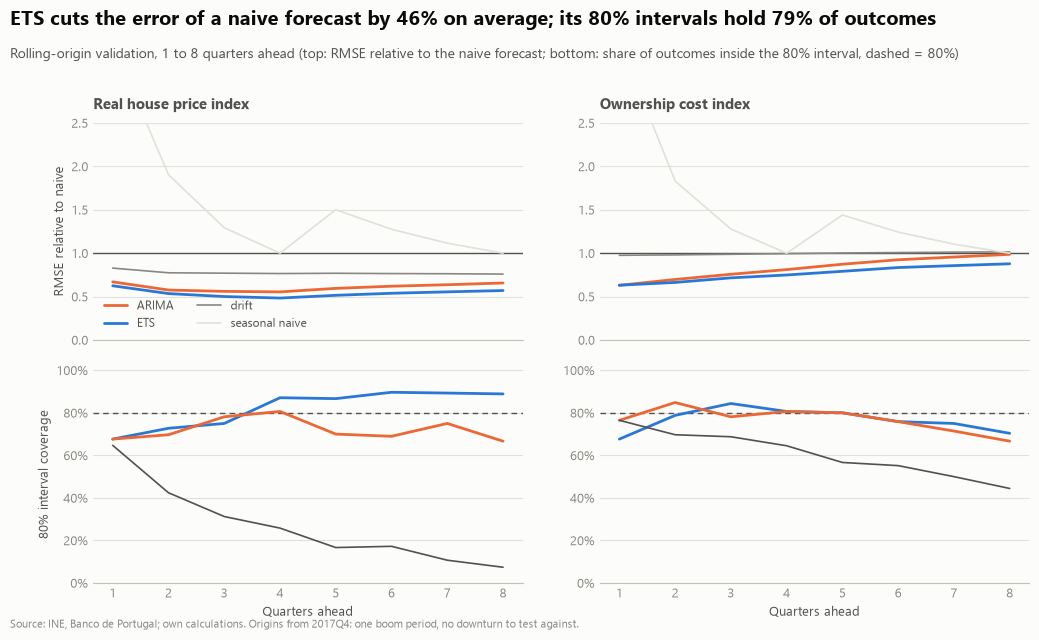

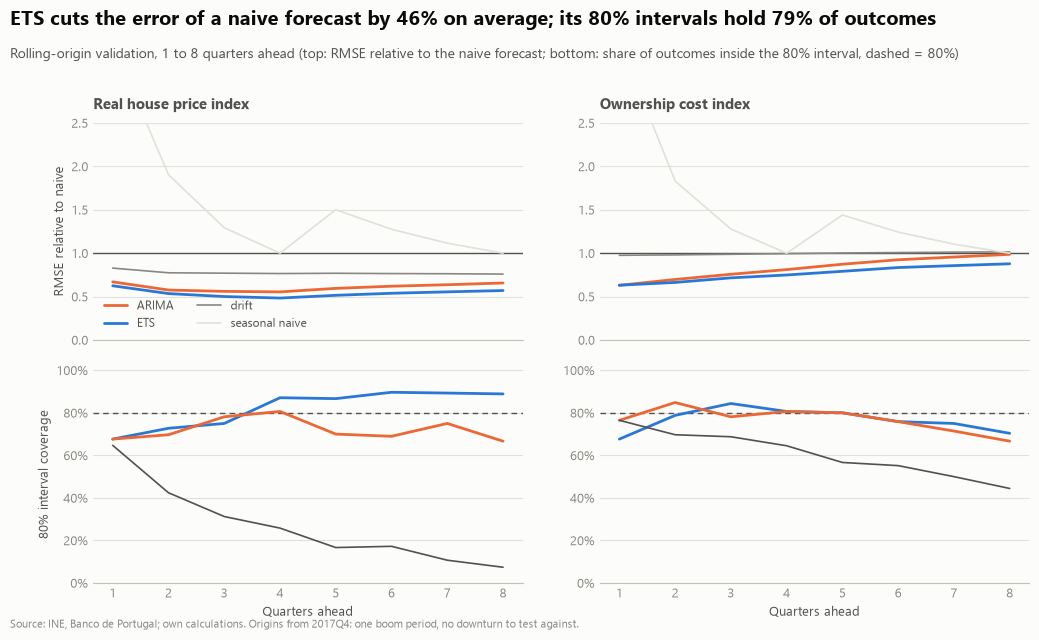

In [4]:
fig = charts.forecast_accuracy(
    [{"title": name, "rel": relative[name], "acc": accuracy[name]} for name in series]
)
style.save_fig(fig, "p4", "forecast_accuracy")
fig

## Step 2 — Which method, by the rule fixed in advance

In [5]:
mean_rmse = pd.DataFrame({n: a.groupby("method")["rmse"].mean() for n, a in accuracy.items()})
mean_rmse["both"] = mean_rmse.mean(axis=1)
order = mean_rmse.sort_values("both")
print(order.round(4).to_string())
chosen = order.index[0]
print("chosen:", chosen)

                Real house price index  Ownership cost index    both
method                                                              
ETS                             0.0514                0.1448  0.0981
ARIMA                           0.0586                0.1594  0.1090
drift                           0.0733                0.1806  0.1270
naive                           0.0956                0.1800  0.1378
seasonal naive                  0.1242                0.2295  0.1769
chosen: ETS


## Step 3 — Is the result stable?
The validation window is short and sits in a boom. Two checks: a shorter first window (more origins, starting
in 2015), and dropping the origins from 2020Q1 to 2021Q4, when the pandemic hit.

In [6]:
checks = []
covid = (pd.Period("2020Q1"), pd.Period("2021Q4"))
for name, s in series.items():
    for initial in (28, 36):
        res = (
            results[name]
            if initial == INITIAL
            else fc.rolling_origin(s, initial=initial, horizon=HORIZON)
        )
        label = f"first window {initial} quarters"
        for tag, r in (
            (label, res),
            (label + ", without 2020-21 origins", res[~res["origin"].between(*covid)]),
        ):
            a = fc.accuracy(r, fc.mase_scale(s, initial))
            rel = fc.relative_to(a, "naive").mean()
            checks.append(
                pd.DataFrame(
                    {
                        "series": name,
                        "variant": tag,
                        "method": rel.index,
                        "rmse_vs_naive": rel.values,
                    }
                )
            )
checks = pd.concat(checks, ignore_index=True)
stable = checks.pivot_table(
    index=["series", "variant"], columns="method", values="rmse_vs_naive"
).round(2)
style.save_table(stable.reset_index(), "p4", "forecast_accuracy_variants")
stable

method                                                                    ARIMA  \
series                 variant                                                    
Ownership cost index   first window 28 quarters                            0.87   
                       first window 28 quarters, without 2020-21 origins   0.88   
                       first window 36 quarters                            0.83   
                       first window 36 quarters, without 2020-21 origins   0.82   
Real house price index first window 28 quarters                            0.62   
                       first window 28 quarters, without 2020-21 origins   0.60   
                       first window 36 quarters                            0.61   
                       first window 36 quarters, without 2020-21 origins   0.58   

method                                                                     ETS  \
series                 variant                                                   
Ownership cost index   first window 28 quarters                           0.77   
                       first window 28 quarters, without 2020-21 origins  0.74   
                       first window 36 quarters                           0.76   
                       first window 36 quarters, without 2020-21 origins  0.74   
Real house price index first window 28 quarters                           0.53   
                       first window 28 quarters, without 2020-21 origins  0.50   
                       first window 36 quarters                           0.54   
                       first window 36 quarters, without 2020-21 origins  0.51   

method                                                                    drift  \
series                 variant                                                    
Ownership cost index   first window 28 quarters                            1.02   
                       first window 28 quarters, without 2020-21 origins   1.03   
                       first window 36 quarters                            1.00   
                       first window 36 quarters, without 2020-21 origins   0.99   
Real house price index first window 28 quarters                            0.85   
                       first window 28 quarters, without 2020-21 origins   0.87   
                       first window 36 quarters                            0.77   
                       first window 36 quarters, without 2020-21 origins   0.79   

method                                                                    naive  \
series                 variant                                                    
Ownership cost index   first window 28 quarters                             1.0   
                       first window 28 quarters, without 2020-21 origins    1.0   
                       first window 36 quarters                             1.0   
                       first window 36 quarters, without 2020-21 origins    1.0   
Real house price index first window 28 quarters                             1.0   
                       first window 28 quarters, without 2020-21 origins    1.0   
                       first window 36 quarters                             1.0   
                       first window 36 quarters, without 2020-21 origins    1.0   

method                                                                    seasonal naive  
series                 variant                                                            
Ownership cost index   first window 28 quarters                                     1.54  
                       first window 28 quarters, without 2020-21 origins            1.57  
                       first window 36 quarters                                     1.54  
                       first window 36 quarters, without 2020-21 origins            1.58  
Real house price index first window 28 quarters                                     1.56  
                       first window 28 quarters, 

## Step 4 — Two-year forecast with the chosen method
Fitted on all 70 quarters, 8 quarters ahead: the horizon that was validated. Longer horizons are left out on
purpose: an ETS with an undamped trend carried 20 quarters ahead extrapolates the 2013 to 2026 boom (a real price
index of 178 in 2031, 80% range 91 to 348), and nothing in the validation supports that. The 5 to 10 year paths
come from scenarios in the simulator, with this forecast as the starting point.

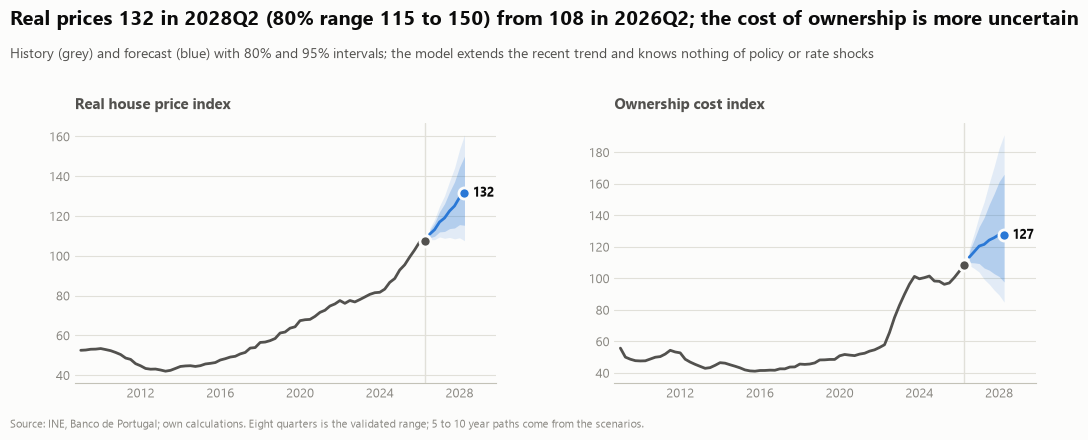

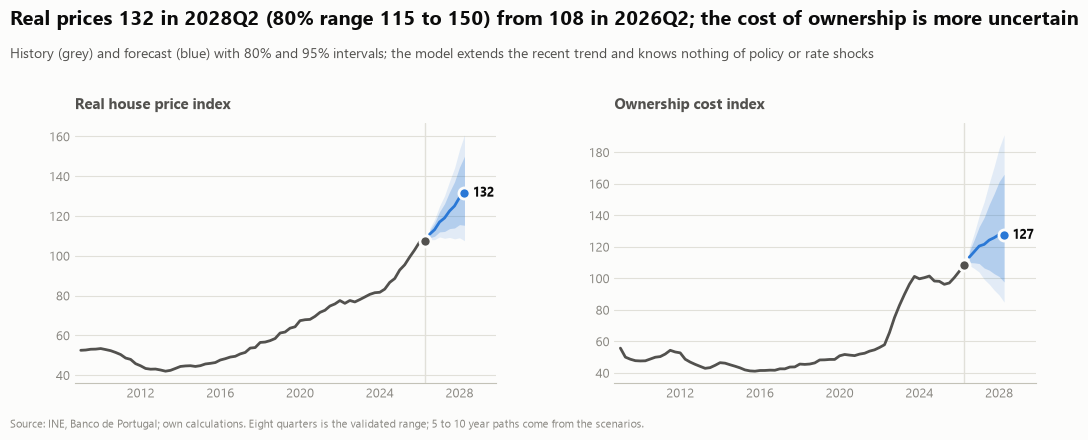

In [7]:
H = HORIZON
fan = {}
for name, s in series.items():
    out = fc.METHODS[chosen](s, H)
    fan[name] = np.exp(out)
rows = []
for name, f in fan.items():
    rows.append(f.reset_index(names="period").assign(series=name, method=chosen))
forecast_table = pd.concat(rows, ignore_index=True)
forecast_table["period"] = forecast_table["period"].astype(str)
style.save_table(forecast_table.round(3), "p4", "national_forecast")


def as_year(index: pd.PeriodIndex) -> np.ndarray:
    return index.year + (index.quarter - 1) / 4


panels = []
for name, s in series.items():
    hist = np.exp(s)
    f = fan[name]
    panels.append(
        {
            "title": name,
            "history": pd.Series(hist.to_numpy(), index=as_year(hist.index)),
            "forecast": f.set_axis(as_year(f.index)),
            "unit_fmt": "{:.0f}",
        }
    )
end = fan["Real house price index"]
last = np.exp(series["Real house price index"]).iloc[-1]
panels[0]["headline"] = (
    f"Real prices {end['mean'].iloc[-1]:.0f} in {end.index[-1]} (80% range {end['lo80'].iloc[-1]:.0f} to {end['hi80'].iloc[-1]:.0f}) "
    f"from {last:.0f} in {series['Real house price index'].index[-1]}; the cost of ownership is more uncertain"
)
fig = charts.forecast_fans(panels)
style.save_fig(fig, "p4", "national_forecast")
fig

## What this says
See `reports/p4_forecast.md` for the reading, limits and what passes to the simulator. The table of the forecast
is `reports/tables/p4/national_forecast.csv`.